In [8]:
import json
import joblib
import numpy as np
import pandas as pd

from pathlib import Path
from scipy.sparse import load_npz
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

In [9]:
RUTA_PROYECTO = Path("..")

RUTA_MODELOS = (
    RUTA_PROYECTO
    / "models"
    / "primera_iteracion"
    / "vectorizacion"
)

X_train_tfidf = load_npz(
    RUTA_MODELOS / "X_train_tfidf.npz"
)

X_test_tfidf = load_npz(
    RUTA_MODELOS / "X_test_tfidf.npz"
)

y_train = np.load(
    RUTA_MODELOS / "y_train.npy",
    allow_pickle=True
)

y_test = np.load(
    RUTA_MODELOS / "y_test.npy",
    allow_pickle=True
)

vectorizador_tfidf = joblib.load(
    RUTA_MODELOS / "vectorizador_tfidf.joblib"
)

datos_test = pd.read_parquet(
    RUTA_MODELOS / "datos_test.parquet"
)

In [10]:
with open(
    RUTA_MODELOS / "configuracion_vectorizacion.json",
    "r",
    encoding="utf-8"
) as archivo:
    configuracion = json.load(archivo)

configuracion

{'total_resenas': 1485343,
 'resenas_entrenamiento': 1188274,
 'resenas_prueba': 297069,
 'test_size': 0.2,
 'random_state': 42,
 'estratificado': True,
 'numero_caracteristicas': 50000,
 'max_features': 50000,
 'min_df': 5,
 'max_df': 0.95,
 'ngram_min': 1,
 'ngram_max': 2,
 'sublinear_tf': True,
 'dtype': 'float32'}

In [11]:
print("COMPROBACIÓN DE LOS DATOS CARGADOS")
print("----------------------------------")

print(
    "Matriz de entrenamiento:",
    X_train_tfidf.shape
)

print(
    "Matriz de prueba:",
    X_test_tfidf.shape
)

print(
    "Etiquetas de entrenamiento:",
    len(y_train)
)

print(
    "Etiquetas de prueba:",
    len(y_test)
)

print(
    "Tamaño del vocabulario:",
    len(vectorizador_tfidf.vocabulary_)
)

print(
    "¿Coincide entrenamiento?",
    X_train_tfidf.shape[0] == len(y_train)
)

print(
    "¿Coincide prueba?",
    X_test_tfidf.shape[0] == len(y_test)
)

print(
    "¿Coinciden las características?",
    X_train_tfidf.shape[1]
    == X_test_tfidf.shape[1]
)

COMPROBACIÓN DE LOS DATOS CARGADOS
----------------------------------
Matriz de entrenamiento: (1188274, 50000)
Matriz de prueba: (297069, 50000)
Etiquetas de entrenamiento: 1188274
Etiquetas de prueba: 297069
Tamaño del vocabulario: 50000
¿Coincide entrenamiento? True
¿Coincide prueba? True
¿Coinciden las características? True


In [12]:
# modelo base
clase_mayoritaria = pd.Series(
    y_train
).mode()[0]

predicciones_base = np.full(
    len(y_test),
    clase_mayoritaria
)

accuracy_base = accuracy_score(
    y_test,
    predicciones_base
)

f1_macro_base = f1_score(
    y_test,
    predicciones_base,
    average="macro",
    zero_division=0
)

print("MODELO BASE")
print("-----------")
print(
    "Clase mayoritaria:",
    clase_mayoritaria
)

print(
    "Accuracy:",
    f"{accuracy_base:.4f}"
)

print(
    "F1-score macro:",
    f"{f1_macro_base:.4f}"
)

MODELO BASE
-----------
Clase mayoritaria: positivo
Accuracy: 0.7601
F1-score macro: 0.2879


In [13]:
# modelo naive bayes

from sklearn.naive_bayes import MultinomialNB


modelo_naive_bayes = MultinomialNB(
    alpha=1.0
)

In [14]:
# Entrenar modelo

from time import perf_counter


inicio_entrenamiento = perf_counter()

modelo_naive_bayes.fit(
    X_train_tfidf,
    y_train
)

tiempo_entrenamiento = (
    perf_counter() - inicio_entrenamiento
)

print("ENTRENAMIENTO COMPLETADO")
print("------------------------")
print(
    "Tiempo de entrenamiento:",
    f"{tiempo_entrenamiento:.2f} segundos"
)

ENTRENAMIENTO COMPLETADO
------------------------
Tiempo de entrenamiento: 3.97 segundos


In [15]:
inicio_prediccion = perf_counter()

predicciones_nb = modelo_naive_bayes.predict(
    X_test_tfidf
)

tiempo_prediccion = (
    perf_counter() - inicio_prediccion
)

print("PREDICCIÓN COMPLETADA")
print("---------------------")
print(
    "Reseñas clasificadas:",
    f"{len(predicciones_nb):,}"
)
print(
    "Tiempo de predicción:",
    f"{tiempo_prediccion:.2f} segundos"
)
print(
    "¿Hay una predicción por reseña?",
    len(predicciones_nb) == len(y_test)
)

PREDICCIÓN COMPLETADA
---------------------
Reseñas clasificadas: 297,069
Tiempo de predicción: 0.11 segundos
¿Hay una predicción por reseña? True


In [16]:
# Métricas
accuracy_nb = accuracy_score(
    y_test,
    predicciones_nb
)

precision_macro_nb = precision_score(
    y_test,
    predicciones_nb,
    average="macro",
    zero_division=0
)

recall_macro_nb = recall_score(
    y_test,
    predicciones_nb,
    average="macro",
    zero_division=0
)

f1_macro_nb = f1_score(
    y_test,
    predicciones_nb,
    average="macro",
    zero_division=0
)

print("MÉTRICAS DE NAIVE BAYES")
print("-----------------------")
print(f"Accuracy:        {accuracy_nb:.4f}")
print(f"Precision macro: {precision_macro_nb:.4f}")
print(f"Recall macro:    {recall_macro_nb:.4f}")
print(f"F1-score macro:  {f1_macro_nb:.4f}")

MÉTRICAS DE NAIVE BAYES
-----------------------
Accuracy:        0.8522
Precision macro: 0.6715
Recall macro:    0.6196
F1-score macro:  0.6383


In [17]:
# Informe

print(
    classification_report(
        y_test,
        predicciones_nb,
        labels=[
            "negativo",
            "neutral",
            "positivo"
        ],
        digits=4,
        zero_division=0
    )
)

              precision    recall  f1-score   support

    negativo     0.7727    0.7073    0.7385     47697
     neutral     0.3463    0.2007    0.2542     23558
    positivo     0.8955    0.9508    0.9223    225814

    accuracy                         0.8522    297069
   macro avg     0.6715    0.6196    0.6383    297069
weighted avg     0.8322    0.8522    0.8398    297069



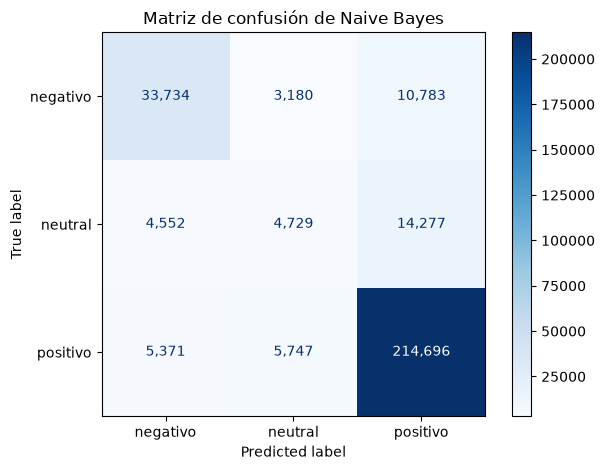

In [18]:
# Matriz de confusión

from matplotlib import pyplot as plt


orden_clases = [
    "negativo",
    "neutral",
    "positivo"
]

ConfusionMatrixDisplay.from_predictions(
    y_test,
    predicciones_nb,
    labels=orden_clases,
    cmap="Blues",
    values_format=","
)

plt.title(
    "Matriz de confusión de Naive Bayes"
)

plt.tight_layout()
plt.show()

In [19]:
# Comparación con el modelo base

resultados_nb = pd.DataFrame([
    {
        "Modelo": "Clase mayoritaria",
        "Accuracy": accuracy_base,
        "Precision macro": precision_score(
            y_test,
            predicciones_base,
            average="macro",
            zero_division=0
        ),
        "Recall macro": recall_score(
            y_test,
            predicciones_base,
            average="macro",
            zero_division=0
        ),
        "F1 macro": f1_macro_base,
        "Tiempo entrenamiento": 0.0,
        "Tiempo predicción": 0.0
    },
    {
        "Modelo": "Multinomial Naive Bayes",
        "Accuracy": accuracy_nb,
        "Precision macro": precision_macro_nb,
        "Recall macro": recall_macro_nb,
        "F1 macro": f1_macro_nb,
        "Tiempo entrenamiento": tiempo_entrenamiento,
        "Tiempo predicción": tiempo_prediccion
    }
])

resultados_nb.round(4)

,Modelo,Accuracy,Precision macro,Recall macro,F1 macro,Tiempo entrenamiento,Tiempo predicción
0,Clase mayoritaria,0.7601,0.2534,0.3333,0.2879,0.0000,0.0000
1,Multinomial Naive Bayes,0.8522,0.6715,0.6196,0.6383,3.9723,0.1087


In [20]:
# Guardar resultados
RUTA_NAIVE_BAYES = (
    RUTA_PROYECTO
    / "models"
    / "primera_iteracion"
    / "naive_bayes"
)

RUTA_NAIVE_BAYES.mkdir(
    parents=True,
    exist_ok=True
)

ruta_resultados_nb = (
    RUTA_NAIVE_BAYES
    / "resultados_naive_bayes.csv"
)

resultados_nb.to_csv(
    ruta_resultados_nb,
    index=False
)

print(
    "Resultados guardados en:",
    ruta_resultados_nb.resolve()
)


Resultados guardados en: C:\Users\Paula María\Desktop\IS\5º CURSO\TFG\Trabajo-Fin-de-Grado\models\primera_iteracion\naive_bayes\resultados_naive_bayes.csv


In [21]:
# Guardar modelo

joblib.dump(
    modelo_naive_bayes,
    RUTA_NAIVE_BAYES
    / "modelo_naive_bayes.joblib"
)

print("Modelo Naive Bayes guardado correctamente.")

Modelo Naive Bayes guardado correctamente.


In [22]:
# Guardar predicciones

np.save(
    RUTA_NAIVE_BAYES
    / "predicciones_naive_bayes.npy",
    predicciones_nb
)

print("Predicciones Naive Bayes guardadas correctamente")

Predicciones Naive Bayes guardadas correctamente


In [23]:
# Guardar métricas

metricas_naive_bayes = {
    "modelo": "Multinomial Naive Bayes",
    "accuracy": float(accuracy_nb),
    "precision_macro": float(precision_macro_nb),
    "recall_macro": float(recall_macro_nb),
    "f1_macro": float(f1_macro_nb),
    "tiempo_entrenamiento_segundos": float(
        tiempo_entrenamiento
    ),
    "tiempo_prediccion_segundos": float(
        tiempo_prediccion
    ),
    "numero_resenas_entrenamiento": int(
        len(y_train)
    ),
    "numero_resenas_prueba": int(
        len(y_test)
    ),
    "numero_caracteristicas": int(
        X_train_tfidf.shape[1]
    ),
    "alpha": float(
        modelo_naive_bayes.alpha
    ),
    "convergencia_alcanzada": None
}

with open(
    RUTA_NAIVE_BAYES / "metricas_naive_bayes.json",
    "w",
    encoding="utf-8"
) as archivo:
    json.dump(
        metricas_naive_bayes,
        archivo,
        indent=4,
        ensure_ascii=False
    )

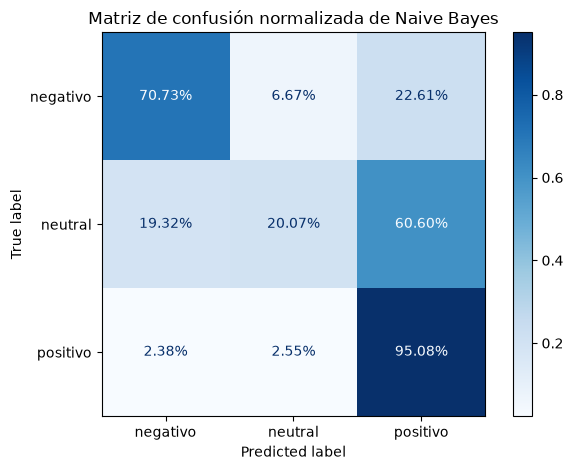

In [24]:
# Guardar Matriz de confusión

orden_clases = [
    "negativo",
    "neutral",
    "positivo"
]

ConfusionMatrixDisplay.from_predictions(
    y_test,
    predicciones_nb,
    labels=orden_clases,
    normalize="true",
    cmap="Blues",
    values_format=".2%"
)

plt.title(
    "Matriz de confusión normalizada de Naive Bayes"
)

plt.tight_layout()

plt.savefig(
    RUTA_NAIVE_BAYES
    / "matriz_confusion_naive_bayes.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [25]:
# Guardar informe de clasificación por clase

informe_naive_bayes = classification_report(
    y_test,
    predicciones_nb,
    labels=[
        "negativo",
        "neutral",
        "positivo"
    ],
    output_dict=True,
    zero_division=0
)

informe_naive_bayes_df = (
    pd.DataFrame(informe_naive_bayes)
    .transpose()
)

informe_naive_bayes_df.to_csv(
    RUTA_NAIVE_BAYES
    / "informe_clasificacion_naive_bayes.csv"
)


In [26]:
# Guardar matriz de confusión normalizada

figura, eje = plt.subplots(
    figsize=(8, 6)
)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    predicciones_nb,
    labels=[
        "negativo",
        "neutral",
        "positivo"
    ],
    normalize="true",
    cmap="Blues",
    values_format=".2%",
    ax=eje
)

eje.set_title(
    "Matriz de confusión normalizada de Naive Bayes"
)

figura.tight_layout()

figura.savefig(
    RUTA_NAIVE_BAYES
    / "matriz_confusion_normalizada_naive_bayes.png",
    dpi=300,
    bbox_inches="tight"
)

plt.close(figura)

In [27]:
# Guardar textos junto con predicciones

datos_test_nb = datos_test.copy()

datos_test_nb["sentiment_predicted"] = (
    predicciones_nb
)

datos_test_nb["prediccion_correcta"] = (
    datos_test_nb["sentiment"]
    == datos_test_nb["sentiment_predicted"]
)

datos_test_nb.to_parquet(
    RUTA_NAIVE_BAYES
    / "resultados_predicciones_naive_bayes.parquet",
    index=False
)